### Domain **SEA Transportation**

### Focus **Forecast demand**

### Business challenge/requirement
SeaPort is the largest operator of Sea Planes across sea shores in Europe. SeaPort doesn't have planes of their own, rather they lease them on a short-term basis based on passenger traffic. You as an ML expert have to build a model to forecast the demand (passenger traffic) of traffic.

### Key issues
As of now, utilization of Planes is low due to poor forecasts of traffic

### Considerations
NONE

### Data volume
* Approx 144 records – data month-wise for last 12 years – file `SeaPlaneTravel.csv`

### Fields in Data
* **`Month`**: Month in which traffic data was recorded
* **`#Passenger`**: No of travelers availing Service in that month

### Additional information
* NA

### Business benefits
Better utilization of planes will lead to a decrease in cost and hence better bottom line

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA # Corrected ARIMA import

In [127]:
df = pd.read_csv('SeaPlaneTravel.csv',parse_dates=['Month'])
df.set_index('Month', inplace=True)
display(df.head())
#df.info()

,#Passengers
Month,
2003-01-01,112
2003-02-01,118
2003-03-01,132
2003-04-01,129
2003-05-01,121


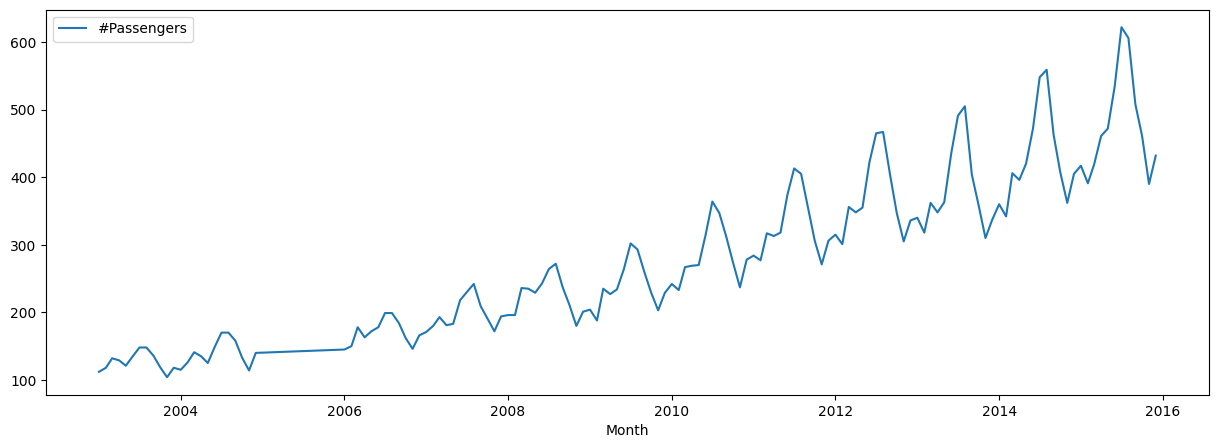

In [128]:
plt.figure(figsize=(15,5))
sns.lineplot(data=df)
plt.show()

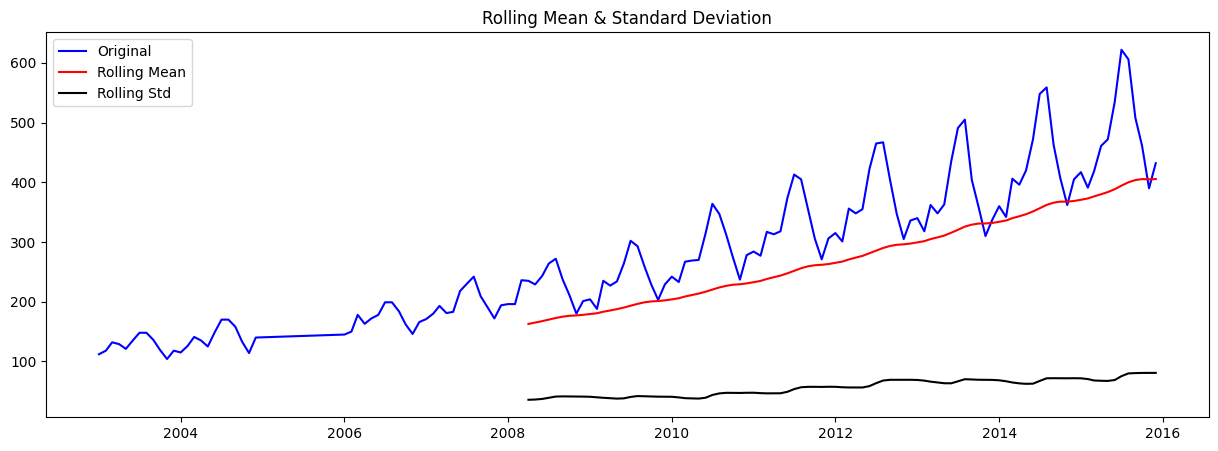

Results of Dickey-Fuller Test:
Test Statistic                   0.815369
p-value                          0.991880
#Lags Used                      13.000000
Number of Observations Used    130.000000
Critical Value (1%)             -3.481682
Critical Value (5%)             -2.884042
Critical Value (10%)            -2.578770
dtype: float64


In [129]:
def test_stationarity(timeseries):
    rolmean = timeseries.rolling(window=52,center=False).mean()
    rolstd = timeseries.rolling(window=52,center=False).std()

    plt.figure(figsize=(15,5))
    orig = plt.plot(timeseries, color='blue',label='Original')
    mean = plt.plot(rolmean, color='red', label='Rolling Mean')
    std = plt.plot(rolstd, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean & Standard Deviation')
    plt.show(block=False)

    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput)

test_stationarity(df)

### Making the Time Series Stationary

As observed from the Dickey-Fuller test results and the rolling statistics plot, the time series is non-stationary. This means its statistical properties (like mean and variance) change over time. Many time series models, such as ARIMA, assume stationarity.

To achieve stationarity, we will apply the following steps:
1.  **Log Transformation**: This helps in stabilizing the variance of the series.
2.  **Differencing**: This helps in removing the trend and seasonality components.

Let's start by applying a log transformation to the `#Passengers` column.

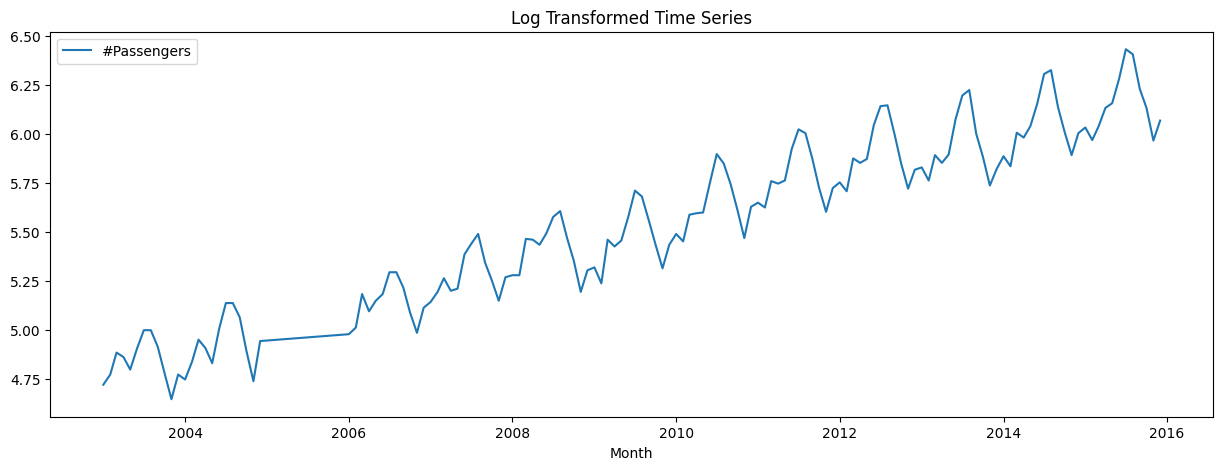


 Results after Log Transformation: 



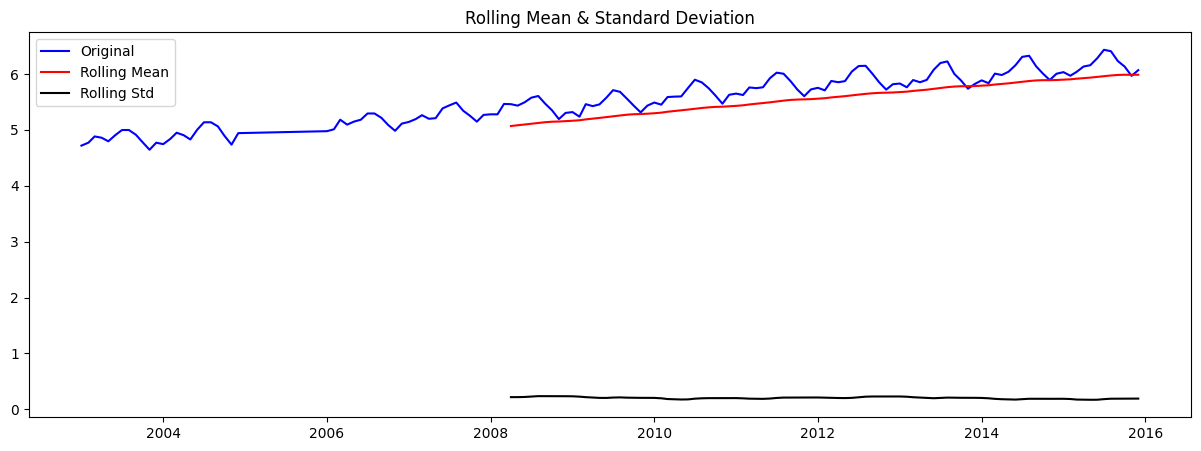

Results of Dickey-Fuller Test:
Test Statistic                  -1.717017
p-value                          0.422367
#Lags Used                      13.000000
Number of Observations Used    130.000000
Critical Value (1%)             -3.481682
Critical Value (5%)             -2.884042
Critical Value (10%)            -2.578770
dtype: float64


In [130]:
df_log = np.log(df)
df_log

plt.figure(figsize=(15,5))
sns.lineplot(data=df_log)
plt.title('Log Transformed Time Series')
plt.show()

# Test stationarity of the log-transformed series
print('\n Results after Log Transformation: \n')
test_stationarity(df_log)

The log transformation has helped stabilize the variance, but the trend is still clearly visible, and the series remains non-stationary (p-value is still high). Next, we will apply differencing to remove the trend component.

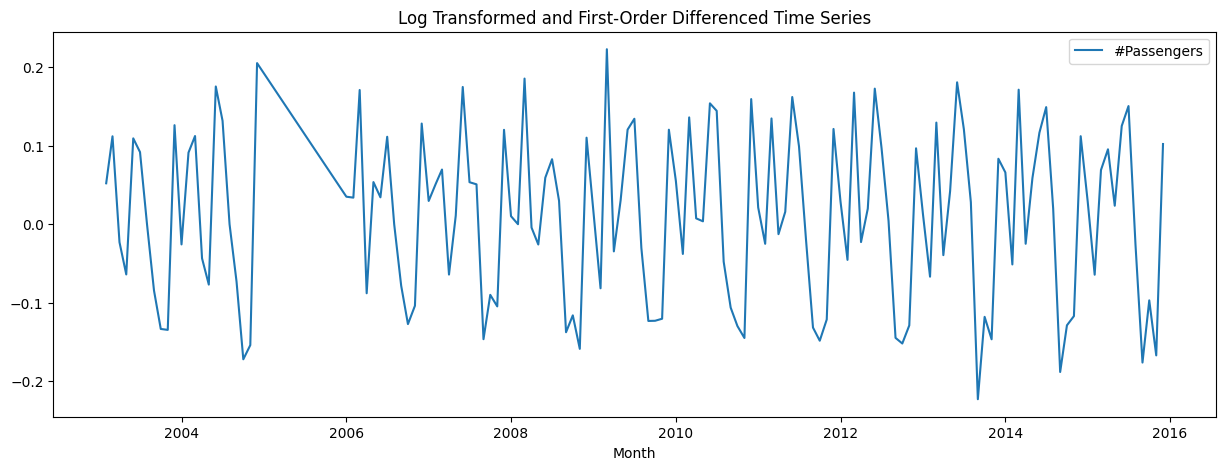

Results after Log Transformation and First-Order Differencing:


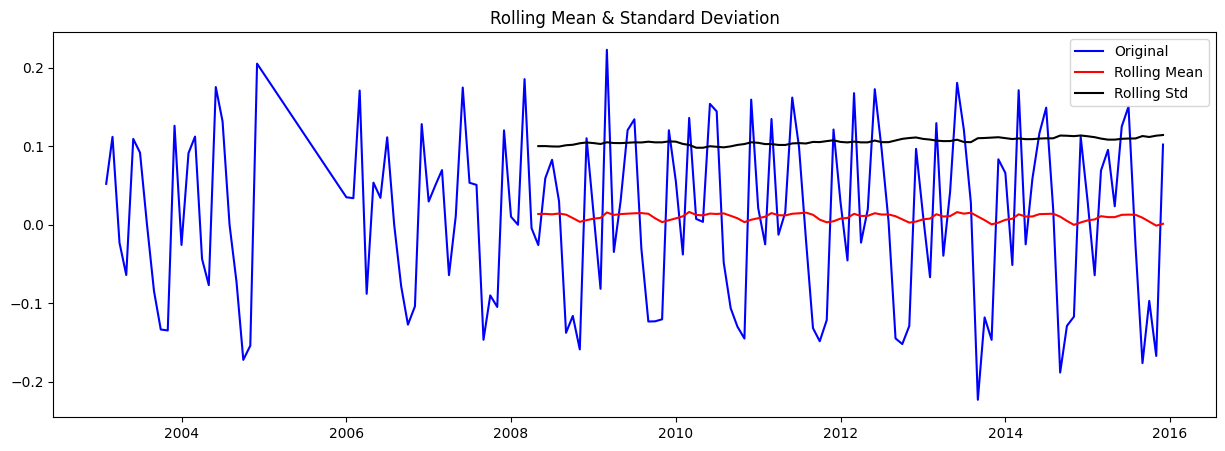

Results of Dickey-Fuller Test:
Test Statistic                  -2.717131
p-value                          0.071121
#Lags Used                      14.000000
Number of Observations Used    128.000000
Critical Value (1%)             -3.482501
Critical Value (5%)             -2.884398
Critical Value (10%)            -2.578960
dtype: float64


In [131]:
# Apply first-order differencing to the log-transformed series
df_log_diff = df_log.diff().dropna()

# Plot the differenced series
plt.figure(figsize=(15,5))
sns.lineplot(data=df_log_diff)
plt.title('Log Transformed and First-Order Differenced Time Series')
plt.show()

# Test stationarity of the differenced series
print('Results after Log Transformation and First-Order Differencing:')
test_stationarity(df_log_diff)

### Applying Seasonal Differencing

The previous step of first-order differencing improved stationarity, but the p-value is still borderline, suggesting that seasonal patterns might remain. For monthly data, a common seasonal period is 12 months. We will apply a seasonal difference of 12 periods to the log-transformed series to remove any yearly seasonality.

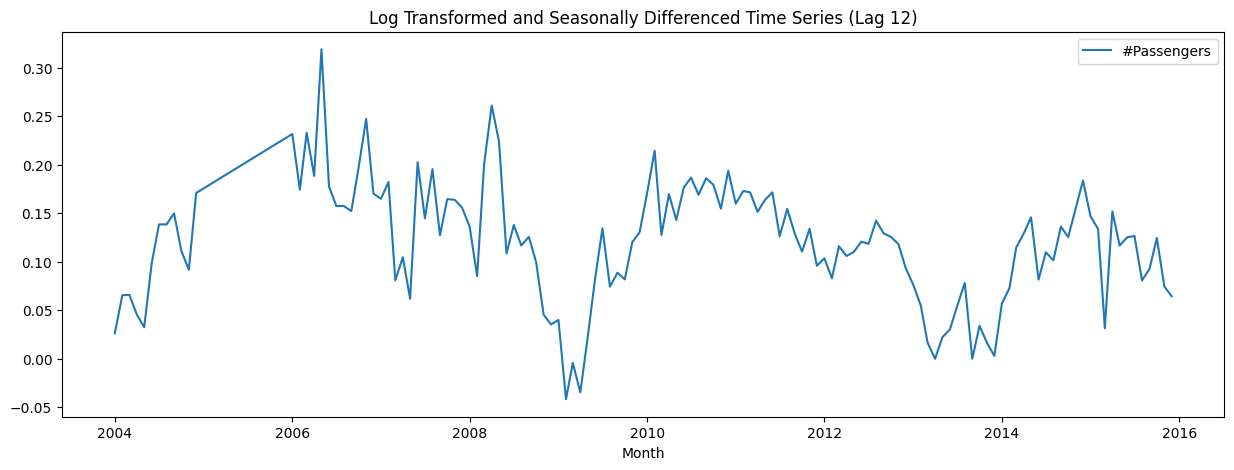

Results after Log Transformation and Seasonal Differencing (Lag 12):


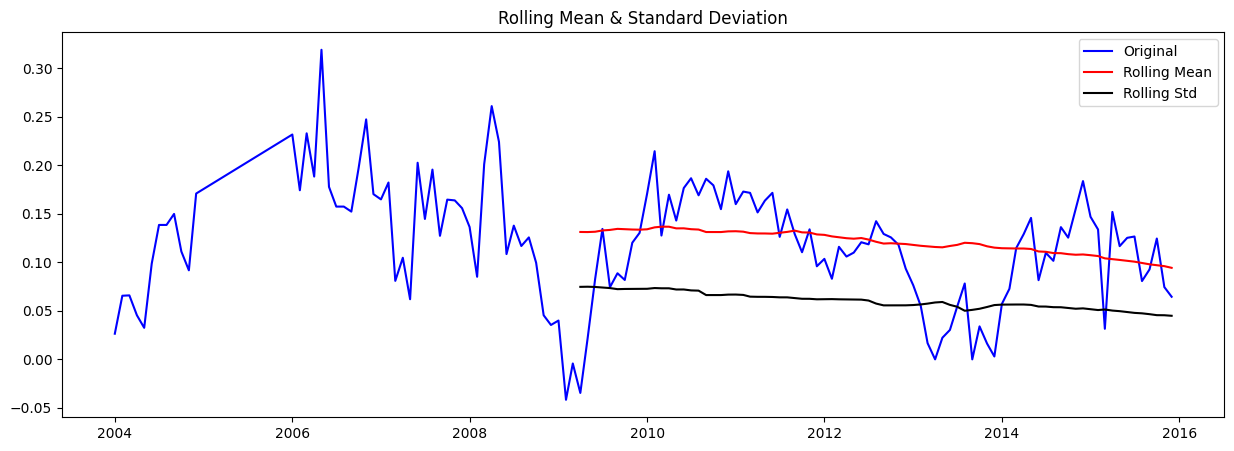

Results of Dickey-Fuller Test:
Test Statistic                  -2.709577
p-value                          0.072396
#Lags Used                      12.000000
Number of Observations Used    119.000000
Critical Value (1%)             -3.486535
Critical Value (5%)             -2.886151
Critical Value (10%)            -2.579896
dtype: float64


In [132]:
# Apply seasonal differencing (12 periods) to the log-transformed series
df_log_seasonal_diff = df_log.diff(12).dropna()

# Plot the seasonally differenced series
plt.figure(figsize=(15,5))
sns.lineplot(data=df_log_seasonal_diff)
plt.title('Log Transformed and Seasonally Differenced Time Series (Lag 12)')
plt.show()

# Test stationarity of the seasonally differenced series
print('Results after Log Transformation and Seasonal Differencing (Lag 12):')
test_stationarity(df_log_seasonal_diff)

### Combining First-Order and Seasonal Differencing

Since neither first-order differencing alone nor seasonal differencing alone fully achieved stationarity (p-value still above 0.05), we will now apply both transformations sequentially to the log-transformed series. This is a common practice for time series with both trend and seasonal components.

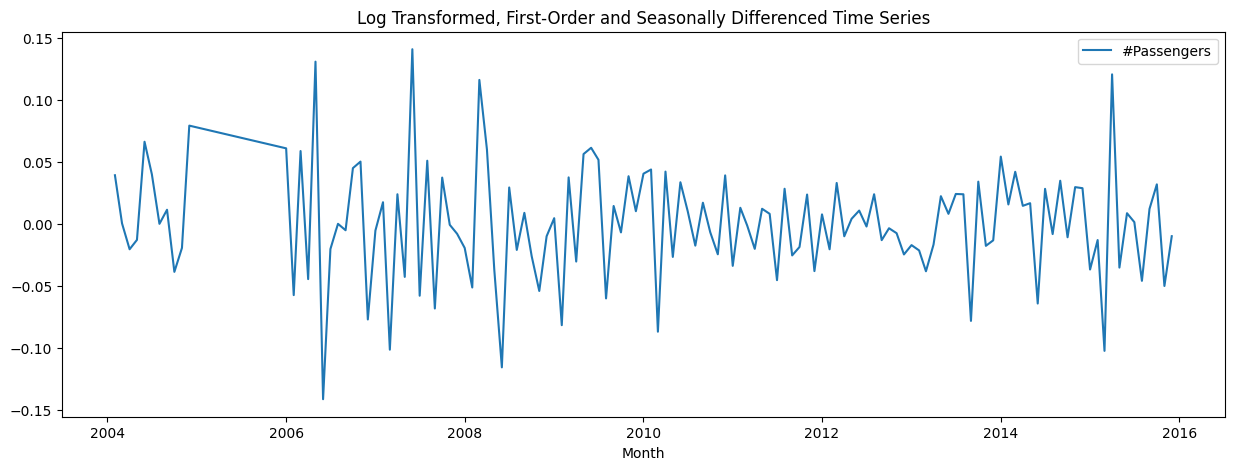

Results after Log Transformation, First-Order and Seasonal Differencing:


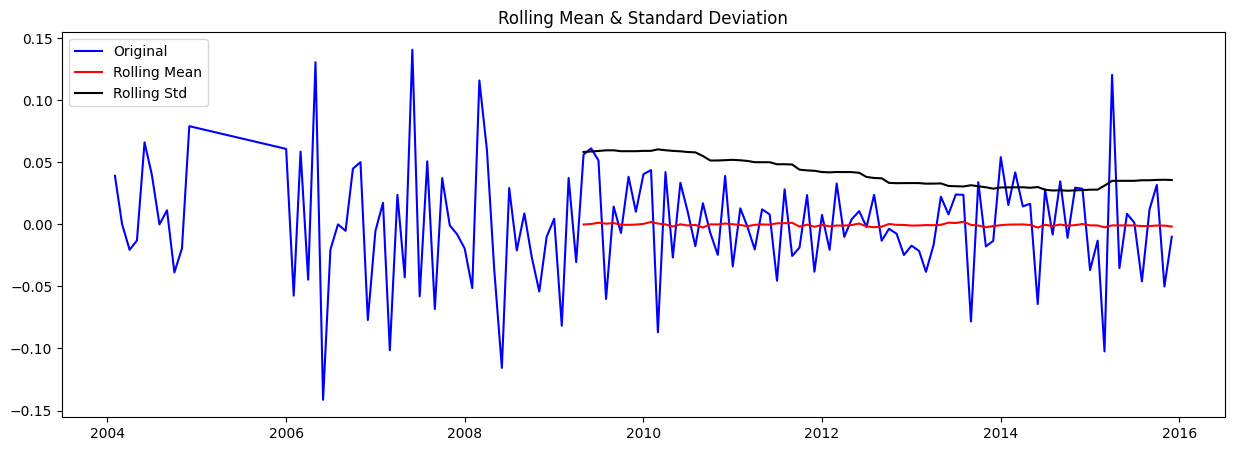

Results of Dickey-Fuller Test:
Test Statistic                  -4.443325
p-value                          0.000249
#Lags Used                      12.000000
Number of Observations Used    118.000000
Critical Value (1%)             -3.487022
Critical Value (5%)             -2.886363
Critical Value (10%)            -2.580009
dtype: float64


In [133]:
# Apply first-order differencing to the seasonally differenced log series
df_log_diff_seasonal_diff = df_log_seasonal_diff.diff().dropna()

# Plot the combined differenced series
plt.figure(figsize=(15,5))
sns.lineplot(data=df_log_diff_seasonal_diff)
plt.title('Log Transformed, First-Order and Seasonally Differenced Time Series')
plt.show()

# Test stationarity of the combined differenced series
print('Results after Log Transformation, First-Order and Seasonal Differencing:')
test_stationarity(df_log_diff_seasonal_diff)

### Determining ARIMA Model Parameters (p, q)

Now that the time series is stationary, we need to determine the `p` and `q` components of our ARIMA model. The `p` parameter refers to the number of autoregressive (AR) terms, and `q` refers to the number of moving average (MA) terms. We will use the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots to identify these parameters.

*   **ACF plot** shows the correlation between a time series and its lagged values. It helps in identifying the `q` (MA) component.
*   **PACF plot** shows the partial correlation between a time series and its lagged values, removing the influence of intermediate lags. It helps in identifying the `p` (AR) component.

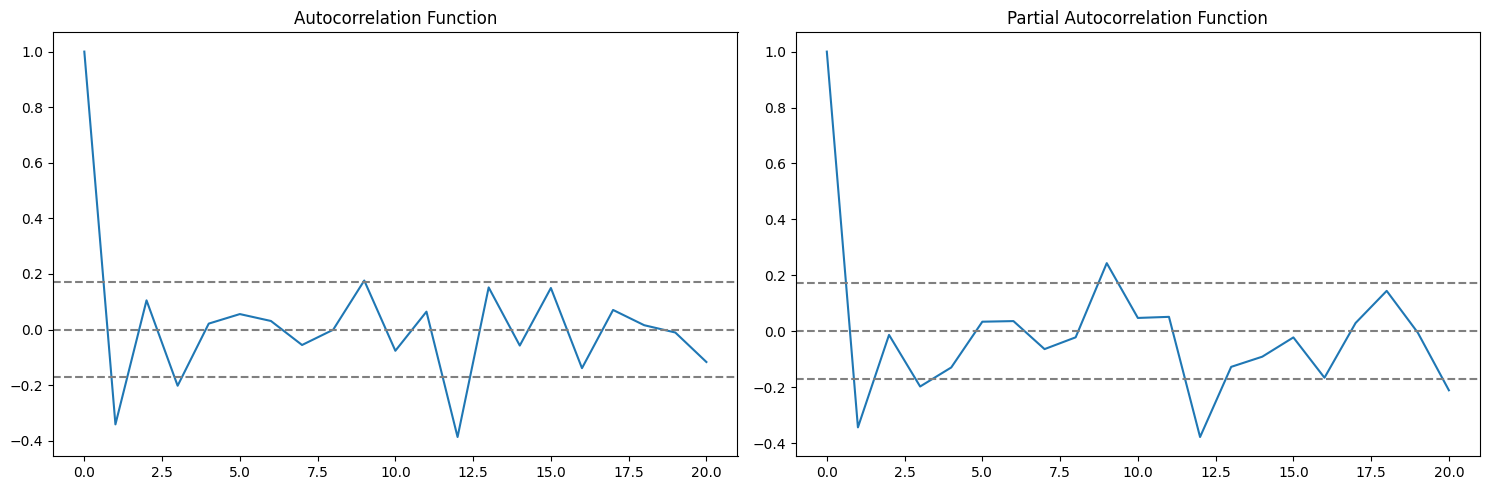

In [134]:
plt.figure(figsize=(15,5))
plt.subplot(121)
plt.plot(acf(df_log_diff_seasonal_diff, nlags=20))
plt.axhline(y=0,linestyle='--',color='gray')
plt.axhline(y=-1.96/np.sqrt(len(df_log_diff_seasonal_diff)),linestyle='--',color='gray')
plt.axhline(y=1.96/np.sqrt(len(df_log_diff_seasonal_diff)),linestyle='--',color='gray')
plt.title('Autocorrelation Function')

plt.subplot(122)
plt.plot(pacf(df_log_diff_seasonal_diff, nlags=20))
plt.axhline(y=0,linestyle='--',color='gray')
plt.axhline(y=-1.96/np.sqrt(len(df_log_diff_seasonal_diff)),linestyle='--',color='gray')
plt.axhline(y=1.96/np.sqrt(len(df_log_diff_seasonal_diff)),linestyle='--',color='gray')
plt.title('Partial Autocorrelation Function')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


RSS:  0.2390963832014925


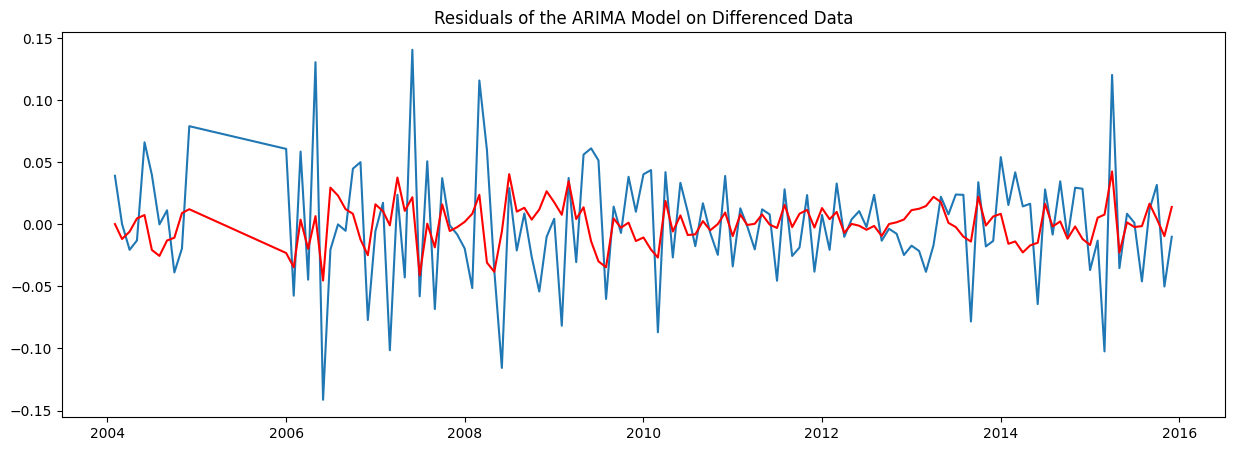

                               SARIMAX Results                                
Dep. Variable:            #Passengers   No. Observations:                  131
Model:                 ARIMA(1, 0, 1)   Log Likelihood                 227.133
Date:                Fri, 14 Aug 2026   AIC                           -446.266
Time:                        20:45:50   BIC                           -434.765
Sample:                             0   HQIC                          -441.593
                                - 131                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.002      0.121      0.904      -0.004       0.004
ar.L1          0.1449      0.187      0.773      0.439      -0.222       0.512
ma.L1         -0.5190      0.163     -3.183      0.0

In [138]:
order = (1, 0, 1) # p=1 (from PACF), d=0 (series is already stationary), q=1 (from ACF)

# Fit the ARIMA model on the already stationary series
model = ARIMA(df_log_diff_seasonal_diff, order=order)
results = model.fit()

residual = results.resid.dropna()
rss = np.sum(residual**2)
print('RSS: ', rss)


# Plot the residuals
plt.figure(figsize=(15,5))
plt.plot(df_log_diff_seasonal_diff)
plt.plot(results.fittedvalues.dropna(),color='red')
plt.title('Residuals of the ARIMA Model on Differenced Data')
plt.show()

# Print the model summary
print(results.summary())

                                      SARIMAX Results                                      
Dep. Variable:                         #Passengers   No. Observations:                  156
Model:             SARIMAX(1, 1, 1)x(0, 1, [], 12)   Log Likelihood                 229.217
Date:                             Fri, 14 Aug 2026   AIC                           -452.434
Time:                                     20:46:24   BIC                           -443.546
Sample:                                 01-01-2003   HQIC                          -448.822
                                      - 12-01-2015                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1633      0.198      0.824      0.410      -0.225       0.552
ma.L1         -0.5455      

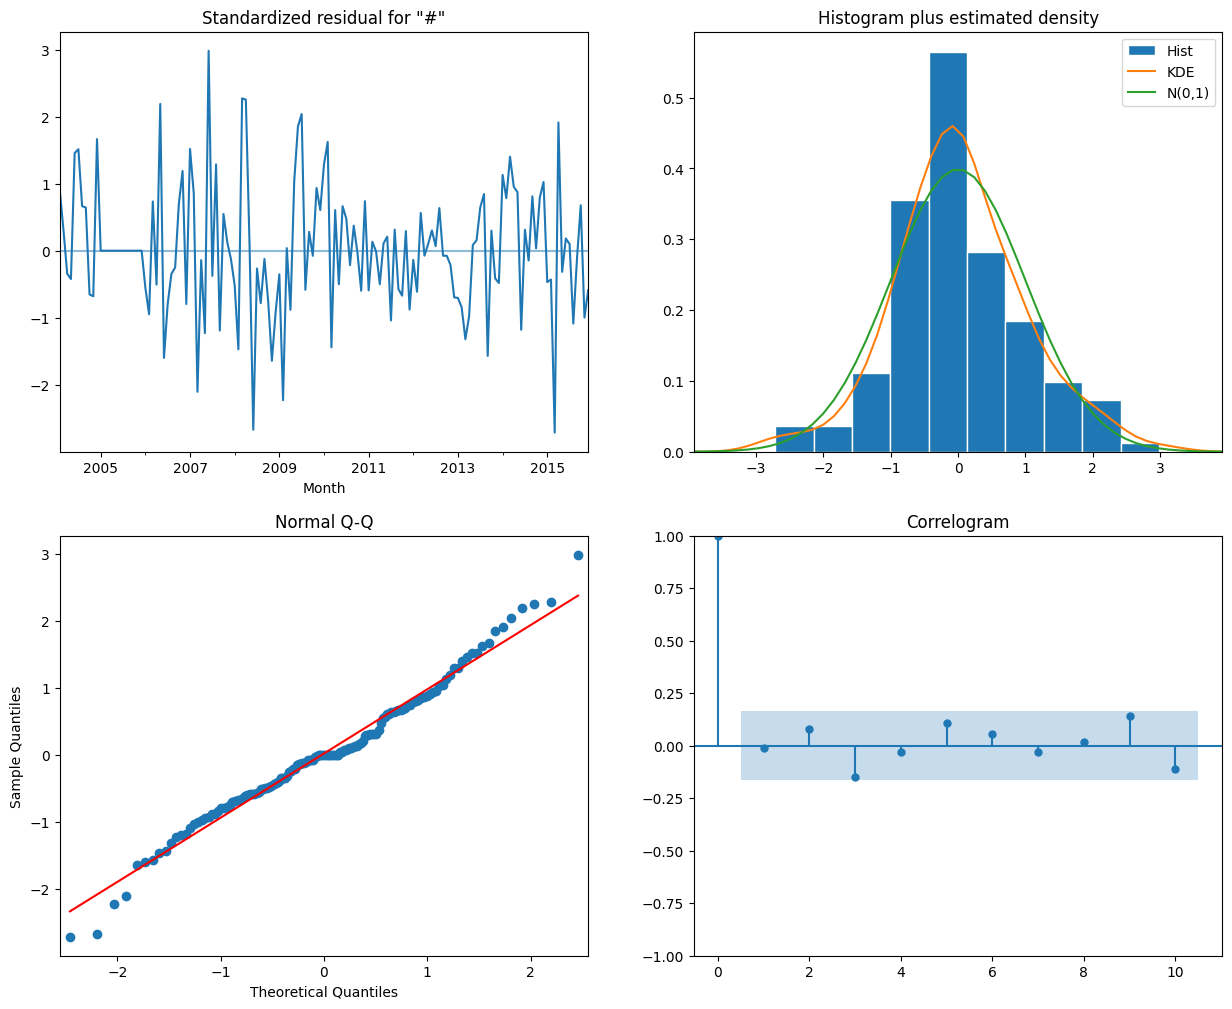

In [139]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Define the non-seasonal and seasonal orders
# We fit on df_log because SARIMAX will handle the differencing internally.
# p=1 (from PACF of original differenced series), d=1 (non-seasonal differencing)
# q=1 (from ACF of original differenced series)
# P=0, D=1, Q=0, S=12 (seasonal differencing of 12 periods)
# A common practice is to allow SARIMAX to handle all differencing (d and D) internally

sarimax_order = (1, 1, 1)  # Non-seasonal (p, d, q)
sarimax_seasonal_order = (0, 1, 0, 12) # Seasonal (P, D, Q, S)

# Ensure the index has frequency information for SARIMAX
df_log = df_log.asfreq('MS') # 'MS' for Month Start

model_sarimax = SARIMAX(df_log, order=sarimax_order, seasonal_order=sarimax_seasonal_order)
results_sarimax = model_sarimax.fit()

print(results_sarimax.summary())

# Plot residuals
results_sarimax.plot_diagnostics(figsize=(15, 12))
plt.show()

### Model Evaluation (Optional Next Steps)

To further evaluate the model, you could consider:

*   **Splitting Data**: For a more rigorous evaluation, split your data into training and testing sets. Train the model on the training data and evaluate its performance on the unseen test data.
*   **Hyperparameter Tuning**: Explore different combinations of `(p, d, q)` and `(P, D, Q, S)` to find an even better model, perhaps by iterating through various orders and comparing their AIC/BIC values or forecast accuracy metrics (like RMSE) on a validation set.
*   **Residual Analysis**: While the diagnostics looked good, a deeper dive into residual plots (e.g., checking for normality, independence more formally) can sometimes reveal subtle issues.
*   **Exogenous Variables**: If there are other factors that influence passenger traffic (e.g., economic indicators, holidays), a SARIMAX model can incorporate them as exogenous variables (`X`).

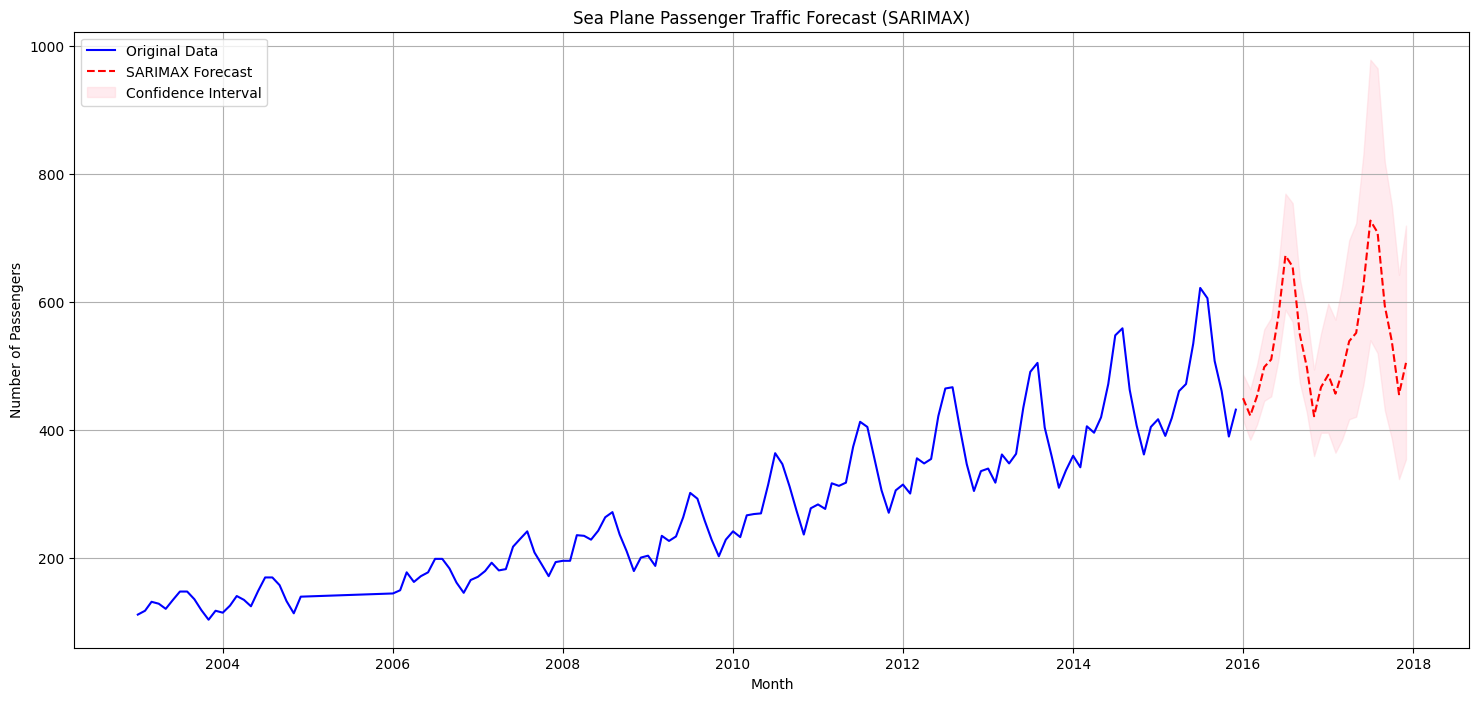

In [141]:
# Plotting the original data with the SARIMAX forecast
plt.figure(figsize=(18, 8))
plt.plot(df.index, df['#Passengers'], label='Original Data', color='blue')
plt.plot(forecast_sarimax.index, forecast_sarimax, label='SARIMAX Forecast', color='red', linestyle='--')
plt.fill_between(conf_int_sarimax.index,
                 conf_int_sarimax.iloc[:, 0],
                 conf_int_sarimax.iloc[:, 1],
                 color='pink', alpha=0.3, label='Confidence Interval')

plt.title('Sea Plane Passenger Traffic Forecast (SARIMAX)')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')
plt.legend()
plt.grid(True)
plt.show()

### Visualizing the SARIMAX Forecast

Finally, let's visualize the original data alongside our SARIMAX forecast and its confidence intervals to see how the model projects future passenger traffic.

In [140]:
# Define the number of steps to forecast (e.g., next 24 months)
forecast_steps = 24

# Get the forecast object
forecast_obj_sarimax = results_sarimax.get_forecast(steps=forecast_steps)

# Get the predicted mean (log-transformed values)
forecast_log_sarimax = forecast_obj_sarimax.predicted_mean

# Get confidence intervals (log-transformed values)
conf_int_sarimax_log = forecast_obj_sarimax.conf_int()

# Inverse transform the forecast and confidence intervals using np.exp
forecast_sarimax = np.exp(forecast_log_sarimax)
conf_int_sarimax = np.exp(conf_int_sarimax_log)

# Display the first few forecasted values and confidence intervals
print("SARIMAX Forecast (Passenger Numbers):")
print(forecast_sarimax.head())
print("\nSARIMAX Confidence Intervals (Passenger Numbers):")
print(conf_int_sarimax.head())

SARIMAX Forecast (Passenger Numbers):
2016-01-01    449.874339
2016-02-01    422.606853
2016-03-01    453.007314
2016-04-01    498.440795
2016-05-01    510.338295
Freq: MS, Name: predicted_mean, dtype: float64

SARIMAX Confidence Intervals (Passenger Numbers):
            lower #Passengers  upper #Passengers
2016-01-01         415.590861         486.985975
2016-02-01         385.009274         463.875975
2016-03-01         408.648847         502.180854
2016-04-01         445.740898         557.371395
2016-05-01         452.735836         575.269627


### Forecasting with SARIMAX and Inverse Transformation

Now that we have a well-fitting SARIMAX model, let's use it to forecast future passenger numbers. We need to perform the following steps:
1.  **Forecast**: Generate future predictions using the `results_sarimax` object.
2.  **Inverse Log Transform**: Convert the forecasted log values back to the original scale by applying `np.exp()`.

Since `SARIMAX` performs differencing internally on `df_log`, its `get_forecast` method directly provides predictions for `df_log` (the log-transformed series). We then simply need to undo the log transformation. This is much simpler than manually inverting differencing steps.

### Fitting a SARIMAX Model

Given the strong seasonality in the data and the challenges with the previous ARIMA model (insignificant AR term, heteroskedasticity, and complex inverse transformation), we will now use a SARIMAX model. SARIMAX is an extension of ARIMA that explicitly handles seasonal components.

The notation for SARIMAX is `SARIMAX(p, d, q)(P, D, Q, S)` where:
*   `(p, d, q)` are the non-seasonal orders (AR, Integrated, MA).
*   `(P, D, Q, S)` are the seasonal orders (Seasonal AR, Seasonal Integrated, Seasonal MA, Seasonal period).

Based on our earlier analysis:
*   **Non-seasonal part `(p, d, q)`:**
    *   `d = 1`: We applied first-order differencing to remove the trend.
    *   `p` and `q`: From the ACF/PACF of the *first-differenced* log series (not the double differenced one), we would typically look for these. However, with SARIMAX, we are applying differencing directly within the model.

*   **Seasonal part `(P, D, Q, S)`:**
    *   `D = 1`: We applied seasonal differencing (12 months) to remove seasonal trend.
    *   `S = 12`: The seasonal period is 12 months.
    *   `P` and `Q`: From the ACF/PACF of the *seasonally differenced* log series at seasonal lags.

Let's try a common approach: applying differencing within the SARIMAX model itself using the log-transformed series `df_log`. This means `d=1` and `D=1` with `S=12`.

For `p` and `q`, and `P` and `Q`, we often start with small values (0 or 1) and refine based on model diagnostics like AIC/BIC or residual analysis. A good starting point for `(P,D,Q,S)` after observing seasonal differencing effectiveness is often `(0,1,0,12)` or `(1,1,1,12)`.

Let's fit a `SARIMAX(1, 1, 1)(0, 1, 0, 12)` model on `df_log` (the log-transformed series) to account for both non-seasonal and seasonal differencing directly within the model.

In [136]:
predictions = pd.Series(results.fittedvalues, copy=True)
display(predictions.head())

,0
Month,
2004-02-01,0.000000
2004-03-01,0.039164
2004-04-01,0.026157
2004-05-01,0.008923
2004-06-01,0.006929


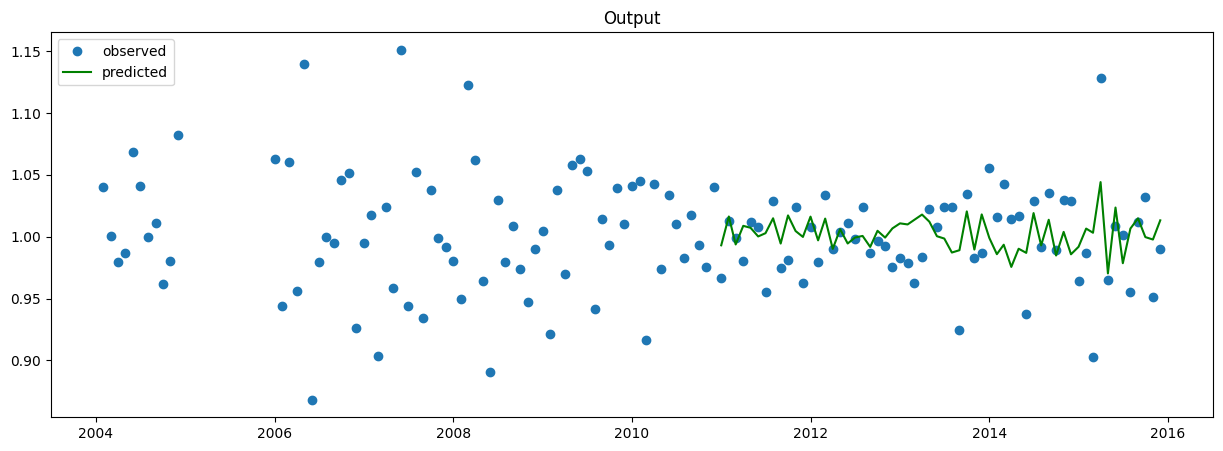

In [137]:
plt.figure(figsize=(15,5))
plt.title('Output')
plt.plot(np.exp(df_log_diff_seasonal_diff), 'o', label='observed')
plt.plot(np.exp(predictions[-60:]), 'g', label='predicted')
legend = plt.legend(loc='upper left')
plt.show()